## Pegasus Evaluation: Tails and Percentiles

Sections B.5 and B.6 of the evaluation of the paper. The evaluation is split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). `2a_base_case.ipynb` describes
the two data sources, the setup (A) and the metrics and methods (B.1) that every notebook uses; the parameters are
defined once in `pegasus/evaluation_setup.py`. B.5 with real data splits the results of B.1 and computes nothing anew. Choose the data source with `data_source` in the first code cell.

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
from pegasus.figures import math_label
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
# the base case of B.1 that this notebook builds on: read from statics/evaluation_cache/ (written by the first
# notebook that needs it), or computed here if the cache is missing or stale (b1_base)
globals().update(b1_base(data_source))
print(f"{data_source} data, {len(seeds)} seeds: chain {' -> '.join(base.path)}, per seed {n_train} training configurations per service and "
      f"{len(base.measured)} held-out configurations, {arrivals}")

base case of B.1 loaded from statics/evaluation_cache/b1_real+b1+b1u-max3_884f34446e6214f4.joblib
real data, 3 seeds: chain detector -> transformer -> compressor, per seed 25 training configurations per service and 120 held-out configurations, poisson arrivals at one rate per configuration (1.58 to 65/s)


## B. Coverage and Tightness of Service Bounds

The metrics, the methods and the rule *validity before tightness* are those of B.1 (`2a_base_case.ipynb`).

### B.5 Varying Tail Behaviors

- **Synthetic:** the execution time of an item gets a lognormal factor whose shape sets how heavy the right tail is
  (`execution_times` in `pegasus/simulation.py`).
- **Real:** a real service has no knob for its tail. The held-out configurations of B.1 are grouped by the tail that
  the testbed measured.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal assume no distribution; the execution-time
  baseline shares the Gaussian assumption. Of the proposed method, only Pegasus Node is evaluated: Pegasus SNC is evaluated in B.1 and B.3 only.

**Setting (real data).** Nothing is computed anew: the results of B.1 are split into three groups of held-out
configurations of equal size. The *tail ratio* of a run is the 99th percentile ÷ the median of the measured processing
time, for the service of the run at which that ratio is largest; a ratio of 1 would be a processing time without any
scatter. The runs are sorted by their tail ratio and cut into thirds. The horizontal axis of the figure shows the
three groups with the median tail ratio of each. Unlike with synthetic data, the groups also differ in their
configurations, so the tail is not the only thing that changes between them, and a group has a third of the held-out
configurations, so one miss weighs three times as much in its coverage.

**Setting (synthetic data).** For every seed, the chain, the training configurations, the held-out configurations and the Poisson
arrivals of B.1. Only the distribution of the execution time changes. The execution time of an item is its mean
execution time (the same function of the configuration as in B.1) multiplied by a factor $e^{\sigma z - \sigma^2/2}$,
where $z$ is the standard normal draw of the item and $\sigma$ the *tail shape*, one value of `execution_tails` per
setting; the Gaussian noise of B.1 is added as before. The factor is lognormal with mean 1, so the mean execution time
and the utilization of every service are the same in every setting. $\sigma = 0$ is the Gaussian execution time of
B.1. With a larger $\sigma$ most items are faster than the mean and a few are several times slower: the squared
coefficient of variation $C^2$ of the factor, variance ÷ mean², is $e^{\sigma^2} - 1$ and is printed in parentheses after
every tick of the figure. The tail and the variance of the execution time therefore grow together.

Every model is trained anew for every $\sigma$, on data with that tail: one execution time per service and training
configuration for Pegasus Node, GP Sum and GP Queue, and each service monitored alone for Quantile Union and
Conformal. No method is told the distribution. Pegasus Node, GP Sum and GP Queue treat an execution time as
Gaussian with the mean and the variance that the model of the service learned; Quantile Union and Conformal learn
latency quantiles and assume no distribution.

**Figure.** The horizontal axis is the tail shape $\sigma$, the vertical axis the tightness, for every seed the median
over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. In the red area below 1× ("underestimated: SLO violated") a method lies under the measured quantile, so a configuration chosen with it to meet a latency SLO would violate the SLO; the legend sits inside the panel where it hides the fewest points. Every line is the
median over the seeds, and the band around it reaches from the smallest to the largest seed. A filled marker means that
the method holds at that $\sigma$ (it reaches the confidence level under every seed, as defined in B.1), a hollow marker
that it does not. A seed under which a method gives no finite latency at half of the held-out configurations or more
counts as infinitely loose, and the method has no point where that is the case for half of the seeds or more; such a
bound is not violated, but it says nothing. The figure is also saved as `figures/tsc/b5_tails_<data source>.pdf` and `.jpg`.

In [2]:
# B.5: execution times of different tail
if data_source == "synthetic":
    # the chains of B.1 with execution times of different tail shape
    execution_tails = [0, 0.25, 0.5, 0.75, 1.0]   # shape sigma of the lognormal factor of the execution time; 0 is the Gaussian execution time of B.1

    def compute():
        tail_methods, tail_truth = {}, {}   # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
        with warnings.catch_warnings():
            # with heavy-tailed training data the fitted GP hyperparameters often end at their bounds, and scikit-learn warns for every such model
            warnings.simplefilter("ignore", ConvergenceWarning)
            for tail in execution_tails:
                for s in seeds:
                    data = chain_data(s, execution_tail=tail)
                    assert same_configurations(data.x_test, bases[s].x_test), "the held-out configurations differ from those of B.1"
                    assert_unseen(data)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                    tail_methods[(tail, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                                 model_seed=seed + s, leave_out=only_base_case + (PROPOSED_SNC,))
                    tail_truth[(tail, s)] = (data.measured, data.measured_low)
        return dict(tail_methods=tail_methods, tail_truth=tail_truth)

    globals().update(cached("b5_tails", data_source, compute, inputs=dict(execution_tails=execution_tails)))
    factor_cv2 = lambda tail: np.expm1(tail ** 2)   # squared coefficient of variation of the lognormal factor with shape `tail`
    tail_label = lambda tail: f"σ = {tail:g}"
    tail_axis = "tail shape σ of the execution time (C² of its factor)"
    tail_ticks = [f"{tail:g} ({factor_cv2(tail):.2f})" for tail in execution_tails]   # one row: the fixed layout of every figure
else:
    # the held-out configurations of B.1 in three groups of equal size, by the measured tail of their processing times; nothing is
    # computed anew, so nothing is cached
    tail_methods, tail_truth = {}, {}   # (tail, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
    tail_ratio = chain_tail_ratios(base_experiment, unthrottled_runs(base_experiment))               # per held-out run: $P_{99}$ / median of the processing time, largest over its services
    tail_group = np.digitize(tail_ratio, np.quantile(tail_ratio, [1 / 3, 2 / 3]))   # 0, 1, 2: lightest to heaviest third
    execution_tails = [float(np.median(tail_ratio[tail_group == g])) for g in range(3)]   # a group is named by its median tail ratio
    for g, tail in enumerate(execution_tails):
        for s, (seed_methods, _) in zip(seeds, per_seed):
            tail_methods[(tail, s)] = {name: (group, latency[tail_group == g]) for name, (group, latency) in seed_methods.items() if name not in only_base_case + (PROPOSED_SNC,)}
            tail_truth[(tail, s)] = (bases[s].measured[tail_group == g], bases[s].measured_low[tail_group == g])
    tail_label = lambda tail: f"tail ratio {tail:.2f}"
    tail_axis = "third of the held-out runs (median tail ratio)"
    tail_ticks = [f"{name} ({tail:.2f})" for name, tail in zip(("lightest", "middle", "heaviest"), execution_tails)]
print(f"{len(tail_methods)} combinations of tail and seed evaluated.")

9 combinations of tail and seed evaluated.


B.5 tail of the execution time, real data: detector → transformer → compressor,
poisson arrivals at one rate per configuration (1.58 to 65/s), 3 seeds
legend_inside: the legend hides 3 points or bands at its best location (upper center)


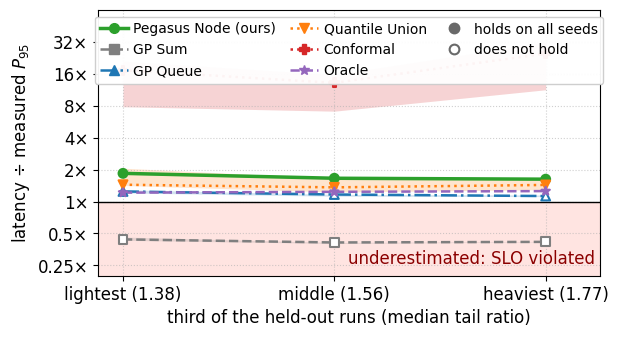

In [3]:
tail_statistics = sweep_statistics(tail_methods, tail_truth, execution_tails, seeds, confidence)   # name -> coverage, tightness, holds, computed
# with real data the three groups are placed at equal distances, because their tail ratios are not spread evenly
tail_positions = execution_tails if data_source == "synthetic" else list(range(len(execution_tails)))
tightness_sweep_figure(tail_positions, tail_statistics, tail_axis,
                       f"B.5 tail of the execution time, {data_source} data: {' → '.join(base.path)},\n{arrivals}, {len(seeds)} seeds", p_label,
                       tick_labels=tail_ticks, log_x=False, name=f"b5_tails_{data_source}")

In [4]:
display(Markdown(
    f"**What this shows** ({data_source} data, {arrivals}, ε = {alpha:g}, {len(seeds)} seeds).\n"
    + sweep_conclusion(execution_tails, tail_statistics, sweep_competitors, tail_label)
    + f"\n- **Finite bounds.** Share of the held-out configurations at which Pegasus Node gives a finite latency (median over the seeds): "
    + "; ".join(f"{name} " + ", ".join(f"{finite_share(tail_methods, name, tail, seeds):.0%} at {tail_label(tail)}" for tail in execution_tails)
                for name in [PROPOSED])
    + ". Where it gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound "
    f"is not violated, but it says nothing.\n"
    + ground_truth_conclusion(execution_tails, tail_truth, tail_statistics, seeds, tail_label, p_label,
                              ", at the same mean execution times" if data_source == "synthetic" else "")
))

**What this shows** (real data, poisson arrivals at one rate per configuration (1.58 to 65/s), ε = 0.05, 3 seeds).
- **Validity.** Methods that hold in every setting in which they are computed, i.e. reach the confidence level under every seed: Pegasus Node (ours), Quantile Union, Conformal. Methods that do not hold, and where: GP Sum at every setting; GP Queue at tail ratio 1.56, tail ratio 1.77.
- **Tightness among the methods that hold** (median over the seeds): Pegasus Node (ours) from 1.84× at tail ratio 1.38 to 1.62× at tail ratio 1.77; Quantile Union from 1.44× at tail ratio 1.38 to 1.43× at tail ratio 1.77; Conformal from 17.23× at tail ratio 1.38 to 24.73× at tail ratio 1.77.
- **Finite bounds.** Share of the held-out configurations at which Pegasus Node gives a finite latency (median over the seeds): Pegasus Node (ours) 100% at tail ratio 1.38, 100% at tail ratio 1.56, 100% at tail ratio 1.77. Where it gives none, the pessimistic mean execution time of a service is so large that the service counts as overloaded; such a bound is not violated, but it says nothing.
- **Ground truth.** The measured $P_{95}$ of the end-to-end latency, the median over the held-out configurations, goes from 0.21 s at tail ratio 1.38 to 0.11 s at tail ratio 1.77. The Oracle, the union bound over measured services, is at 1.21× and 1.25×.

### B.6 Varying Percentiles

- **Synthetic:** every percentile that the simulated runs are long enough to measure, on the chain of B.1.
- **Real:** the same percentiles on every chain of B.1 (`chain_names`), with the held-out runs and the per-service
  models of B.1 on All Chains. A run measured a few hundred to a few thousand requests, so the highest percentiles rest
  on few requests per run, and a percentile beyond $P_{99}$ could not be measured at all: fewer than one request of a
  typical run lies above its $P_{99.9}$. With all chains, the result does not depend on the choice of one chain.
- **Baselines:** as in B.1 without DNN Sum. Quantile Union and Conformal train one model per percentile; the other
  methods use the same execution-time models at every percentile. Of the proposed method, only Pegasus Node is evaluated: Pegasus SNC is evaluated in B.1 and B.3 only.

**Setting.** For every chain and seed, the training configurations, the per-service models, the held-out
configurations, the Poisson arrivals and the simulated or measured runs of B.1. Only the percentile that a method has to bound
changes: the *level* is the share of items whose end-to-end latency must lie under the bound, one value of
`percentile_levels` per setting, written as a percentile (level 0.95 is $P_{95}$, the percentile of B.1). The violation
probability is $\varepsilon$ = 1 − level, so a higher percentile is a smaller $\varepsilon$. The ground truth is the
measured quantile of the end-to-end latency at that level, with the confidence interval of B.1. The highest level is
limited by the length of the runs: a quantile further in the tail would rest on too few items per run to be
measured, in particular the quantile at $1 - \varepsilon / |S|$ that Quantile Union, Conformal and the Oracle read from
the runs of each service. A method *holds on a chain* at a percentile if it reaches the confidence level on that chain
under every seed, as in B.1 on All Chains.

How the level enters each method: Pegasus Node bounds every service at $\varepsilon / |S|$, with the same execution-time models
as in B.1. GP Sum takes the level as the quantile of
its Gaussian sum, and GP Queue as the quantile of its waiting-time formula. Quantile Union and Conformal are trained
anew for every level, on the $(1 - \varepsilon / |S|)$ latency quantile of each service monitored alone.

**Figure.** The horizontal axis is the bounded percentile, at equal distances from the lowest to the highest; the
vertical axis is the tightness, the latency of a method ÷ the measured quantile at that percentile, for every seed the
median over its held-out configurations (logarithmic). The horizontal line at 1× is the measured quantile. In the red area below 1× ("underestimated: SLO violated") a method lies under the measured quantile, so a configuration chosen with it to meet a latency SLO would violate the SLO; the legend sits inside the panel where it hides the fewest points.
- *Synthetic data (one chain):* every line is the median over the seeds, and the band around it reaches from the
  smallest to the largest seed. A filled marker means that the method holds at that percentile, a hollow marker that
  it does not.
- *Real data (all chains):* a chain contributes the median over its seeds; every line is the median over the chains,
  and the band reaches from the chain with the smallest to the chain with the largest value. A filled marker means that
  the method holds at that percentile on every chain, a hollow marker that it fails on at least one; on how many chains
  it holds is in the conclusion below.

Look at the markers first, then at whether a filled line comes closer to 1× or moves away from it toward the higher
percentiles. The figure is also saved as `figures/tsc/b6_percentiles_<data source>.pdf` and `.jpg`.

In [5]:
# B.6: the chains with a different percentile of the end-to-end latency to bound; real data: every chain of B.1, synthetic data: the chain of B.1
percentile_levels = [0.5, 0.75, 0.9, 0.95, 0.99]   # level of the bounded latency quantile; the violation probability is 1 - level, and B.1 uses 1 - alpha
percentile_chains = chain_names if data_source == "real" else [None]   # None: the synthetic chain of B.1 (bases, base_models)


def compute():
    percentile_methods, percentile_truth = {}, {}   # (chain, level, seed) -> name -> (group, latency per held-out configuration) / (measured quantile, its lower edge)
    with warnings.catch_warnings():
        # for some services the fitted GP hyperparameters end at their bounds, and scikit-learn warns for every such model
        warnings.simplefilter("ignore", ConvergenceWarning)
        for chain in percentile_chains:
            for s in seeds:
                # the execution times do not depend on the percentile, so the per-service models of a chain are fitted once (as in B.1) and
                # used at every level; only the ground truth, and the latency quantiles of Quantile Union and Conformal, change with the level
                if chain is None:
                    chain_at = lambda level: chain_data(s, level=level)
                    reference, models = bases[s], base_models[s]
                else:
                    chain_at = lambda level: load_chain_data("real", experiment=chain, level=level, coverage_check=coverage_check, seed=[seed, s],
                                                             n_train=base_options["n_train"], training_campaign=BENCHMARKS_V2)
                    reference = chain_at(1 - alpha)
                    models = fit_services(reference, reference.x_train, reference.y_train, model_seed=seed + s, confidence=confidence, with_dnn=False)
                for level in percentile_levels:
                    data = chain_at(level)
                    assert same_configurations(data.x_test, reference.x_test), "the held-out configurations differ between the percentiles"
                    assert all(np.array_equal(data.y_train[name], reference.y_train[name]) for name in data.path), "the training data differs between the percentiles"
                    percentile_methods[(chain, level, s)], _ = compare_methods(data, models, data.x_train, data.monitored_latencies, 1 - level, confidence,
                                                                               n_calibration, model_seed=seed + s, leave_out=only_base_case + (PROPOSED_SNC,),
                                                                               x_train_load=data.x_train_load)
                    percentile_truth[(chain, level, s)] = (data.measured, data.measured_low)
    return dict(percentile_methods=percentile_methods, percentile_truth=percentile_truth)


globals().update(cached("b6_percentiles", data_source, compute, inputs=dict(percentile_levels=percentile_levels, percentile_chains=percentile_chains)))
print(f"{len(percentile_methods)} combinations of chain, percentile and seed evaluated ({len(percentile_chains)} chains).")

b6_percentiles: results loaded from statics/evaluation_cache/b6_percentiles_real+b1+b1u-max3_c2413ca7497fd70a.joblib
225 combinations of chain, percentile and seed evaluated (15 chains).


B.6 bounded percentile, real data: all 15 chains of B.1, median over the chains (band: range over the chains),
Poisson arrivals at the rate of every run, 3 seeds
legend_inside: the legend hides 5 points or bands at its best location (upper center)
save_figure: b6_percentiles_real reaches beyond the figure by {'bottom': np.float64(0.02)} inches


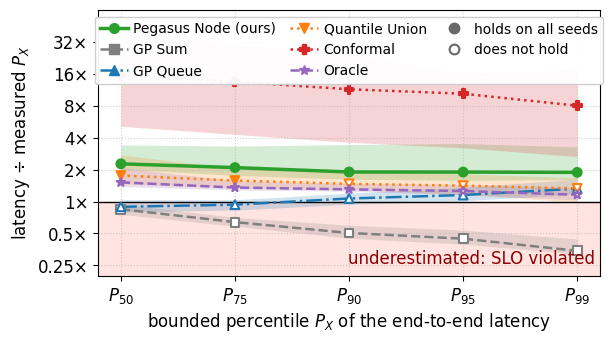

In [6]:
# per chain: coverage, tightness and validity per percentile over the seeds, as in every sweep (name -> dict, see sweep_statistics)
chain_statistics = {chain: sweep_statistics({(level, s): percentile_methods[(chain, level, s)] for level in percentile_levels for s in seeds},
                                            {(level, s): percentile_truth[(chain, level, s)] for level in percentile_levels for s in seeds},
                                            percentile_levels, seeds, confidence) for chain in percentile_chains}
if len(percentile_chains) == 1:   # one chain: the band reaches over the seeds, as in every other sweep
    percentile_statistics = chain_statistics[percentile_chains[0]]
else:                             # several chains: a chain's value is its median over the seeds, and the band reaches over the chains
    names = [name for name in chain_statistics[percentile_chains[0]] if all(name in chain_statistics[chain] for chain in percentile_chains)]
    over_chains = lambda name, key, reduce: np.column_stack([reduce(chain_statistics[chain][name][key]) for chain in percentile_chains])
    percentile_statistics = {name: dict(
        # a chain without a finite tightness under half of its seeds or more has none (nan), as a seed has in sweep_line
        tightness=over_chains(name, "tightness", lambda t: np.where(np.isfinite(np.median(np.nan_to_num(t, nan=np.inf), axis=1)),
                                                                    np.median(np.nan_to_num(t, nan=np.inf), axis=1), np.nan)),
        coverage=over_chains(name, "coverage", lambda c: np.nanmin(c, axis=1)),          # per chain the worst seed
        holds=np.all(over_chains(name, "holds", lambda h: h), axis=1),                   # filled marker: holds on every chain
        computed=np.any(over_chains(name, "computed", lambda c: c), axis=1)) for name in names}
held_chains = {name: np.sum([chain_statistics[chain][name]["holds"] for chain in percentile_chains], axis=0)
               for name in percentile_statistics}   # name -> per percentile: on how many chains the method holds
percentile_label = lambda level: f"$P_{{{100 * level:g}}}$"
scope = (f"{' → '.join(base.path)}, {len(base.measured)} held-out configurations per seed" if len(percentile_chains) == 1 else
         f"all {len(percentile_chains)} chains of B.1, median over the chains (band: range over the chains)")
# the percentiles are placed at equal distances, because neither the level nor the violation probability spreads them evenly
tightness_sweep_figure(list(range(len(percentile_levels))), percentile_statistics, "bounded percentile $P_X$ of the end-to-end latency",
                       f"B.6 bounded percentile, {data_source} data: {scope},\n{arrivals if len(percentile_chains) == 1 else 'Poisson arrivals at the rate of every run'}, "
                       f"{len(seeds)} seeds", "$P_X$",
                       tick_labels=[percentile_label(level) for level in percentile_levels], log_x=False, name=f"b6_percentiles_{data_source}")

In [7]:
if len(percentile_chains) == 1:
    display(Markdown(
        f"**What this shows** ({data_source} data, {arrivals}, {len(seeds)} seeds).\n"
        + sweep_conclusion(percentile_levels, percentile_statistics, sweep_competitors, percentile_label) + "\n"
        + ground_truth_conclusion(percentile_levels, {(level, s): percentile_truth[(None, level, s)] for level in percentile_levels for s in seeds},
                                  percentile_statistics, seeds, percentile_label, "percentile")
    ))
else:
    n_chains, first, last = len(percentile_chains), percentile_levels[0], percentile_levels[-1]
    shown = [name for name in sweep_competitors if name in percentile_statistics]
    # per chain the median over the seeds of the tightness of Pegasus Node at the lowest and the highest percentile (nan: no finite bound)
    pegasus = percentile_statistics[PROPOSED]["tightness"]
    held = lambda level: np.array([chain_statistics[chain][PROPOSED]["holds"][percentile_levels.index(level)] for chain in percentile_chains])
    both = held(first) & held(last) & np.isfinite(pegasus[0]) & np.isfinite(pegasus[-1])
    tighter = int(np.sum(both & (pegasus[-1] < pegasus[0])))
    change = pegasus[-1] / pegasus[0]   # per chain: tightness at the highest ÷ at the lowest percentile, below 1 where the bound tightens
    order = np.argsort(np.where(both, change, np.inf))
    base_rank = int(np.where(np.array(percentile_chains)[order] == base_experiment)[0][0]) + 1
    median_over_held = lambda name, level: np.nanmedian(np.where(
        [chain_statistics[chain][name]["holds"][percentile_levels.index(level)] for chain in percentile_chains],
        percentile_statistics[name]["tightness"][percentile_levels.index(level)], np.nan))
    measured = lambda level: np.median(np.concatenate([percentile_truth[(chain, level, seeds[0])][0] for chain in percentile_chains]))
    display(Markdown(
        f"**What this shows** (real data, all {n_chains} chains of B.1, {len(seeds)} seeds; a method holds on a chain at a percentile if it "
        "reaches the confidence level under every seed).\n"
        "- **Validity across the chains.** Chains on which a method holds, at " + ", ".join(map(percentile_label, percentile_levels))
        + ": " + "; ".join(f"{name} " + ", ".join(str(int(k)) for k in held_chains[name]) for name in shown) + f" (of {n_chains}).\n"
        "- **Tightness on the chains where a method holds** (median over these chains): "
        + "; ".join(f"{name} {median_over_held(name, first):.2f}× at {percentile_label(first)} and {median_over_held(name, last):.2f}× at "
                    f"{percentile_label(last)}" for name in shown if np.isfinite(median_over_held(name, first)) or np.isfinite(median_over_held(name, last))) + ".\n"
        f"- **Toward the tail.** {PROPOSED} holds at both percentiles on {int(both.sum())} chains and becomes tighter from "
        f"{percentile_label(first)} to {percentile_label(last)} on {tighter} of them; the base chain of B.1 ({base_experiment}, the chain of B.5 and "
        f"C.1) has the {base_rank}. largest decrease of the {n_chains} chains (its tightness at {percentile_label(last)} is "
        f"{change[percentile_chains.index(base_experiment)]:.2f} times that at {percentile_label(first)}).\n"
        "- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out runs of all chains: "
        + ", ".join(f"{measured(level):.2f} s at {percentile_label(level)}" for level in (first, last)) + "."
    ))

/tmp/ipykernel_226628/3355666607.py:19: RuntimeWarning: All-NaN slice encountered
  median_over_held = lambda name, level: np.nanmedian(np.where(


**What this shows** (real data, all 15 chains of B.1, 3 seeds; a method holds on a chain at a percentile if it reaches the confidence level under every seed).
- **Validity across the chains.** Chains on which a method holds, at $P_{50}$, $P_{75}$, $P_{90}$, $P_{95}$, $P_{99}$: Pegasus Node (ours) 15, 15, 15, 15, 15; GP Sum 0, 0, 0, 0, 0; GP Queue 2, 2, 2, 2, 8; Quantile Union 15, 15, 14, 12, 8; Conformal 15, 15, 15, 15, 15 (of 15).
- **Tightness on the chains where a method holds** (median over these chains): Pegasus Node (ours) 2.26× at $P_{50}$ and 1.88× at $P_{99}$; GP Queue 1.02× at $P_{50}$ and 1.33× at $P_{99}$; Quantile Union 1.76× at $P_{50}$ and 1.42× at $P_{99}$; Conformal 15.48× at $P_{50}$ and 7.99× at $P_{99}$.
- **Toward the tail.** Pegasus Node (ours) holds at both percentiles on 15 chains and becomes tighter from $P_{50}$ to $P_{99}$ on 14 of them; the base chain of B.1 (b1-vision-1-single+b1u-max3, the chain of B.5 and C.1) has the 4. largest decrease of the 15 chains (its tightness at $P_{99}$ is 0.76 times that at $P_{50}$).
- **Ground truth.** The measured percentile of the end-to-end latency, the median over the held-out runs of all chains: 0.07 s at $P_{50}$, 0.18 s at $P_{99}$.